In [1]:
import cv2
import numpy as np
import heapq
from collections import Counter
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread('input.jpg', cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")
else:
    plt.imshow(img, cmap='gray')
    plt.title("Original Grayscale Image")
    plt.axis('off')
    plt.show()

Image not found!


In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current working directory:
C:\Users\acer

Files available:
['.ai-navigator', '.anaconda', '.android', '.antigravity', '.antigravity-ide', '.bash_history', '.cache', '.conda', '.condarc', '.config', '.continuum', '.copilot', '.docker', '.gemini', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.local', '.mamba', '.matplotlib', '.ollama', '.python_history', '.securecoder', '.viminfo', '.VirtualBox', '.vscode', '.vscode-shared', 'AppData', 'Application Data', 'battery-report.html', 'captured_image.jpg', 'captured_video.mp4', 'Contacts', 'Cookies', 'DIPT EX 3', 'DIPT EX 4', 'Documents', 'Downloads', 'EX 2', 'Favorites', 'FWS', 'github', 'healthchatbot', 'i3q6bSoc4a0', 'IdeaProjects', 'lane_detection_output.jpg', 'Links', 'Local Settings', 'MathServer', 'Module1', 'Music', 'My Documents', 'my-project', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{f38eab6a-876b-11f0-b848-f9053c514127}.TM.blf', 'NTUSER.DAT{f38eab6a-876b-11f0-b848-f9053c514

Image loaded successfully!
Image dimensions: (941, 1672)


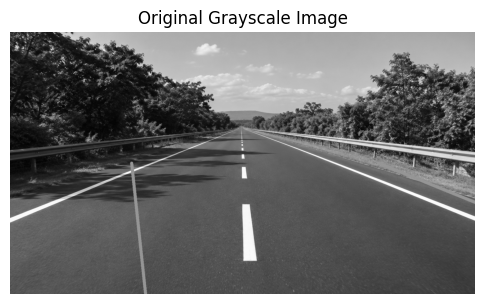

In [5]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('lane_detection_output.jpg', cv2.IMREAD_GRAYSCALE)

if img is not None:
    print("Image loaded successfully!")
    print("Image dimensions:", img.shape)

    plt.figure(figsize=(6, 6))
    plt.imshow(img, cmap='gray')
    plt.title("Original Grayscale Image")
    plt.axis('off')
    plt.show()
else:
    print("Image not found!")

In [6]:
pixels = img.flatten()

from collections import Counter

frequency = Counter(pixels)

print("Pixel Intensity | Frequency")

for pixel, freq in sorted(frequency.items()):
    print(pixel, " | ", freq)

Pixel Intensity | Frequency
0  |  15
1  |  24
2  |  55
3  |  198
4  |  573
5  |  1238
6  |  1843
7  |  2594
8  |  3751
9  |  4997
10  |  6055
11  |  7080
12  |  8055
13  |  8624
14  |  9093
15  |  8949
16  |  9296
17  |  9232
18  |  9081
19  |  9199
20  |  9101
21  |  8841
22  |  8606
23  |  8501
24  |  8396
25  |  8217
26  |  8063
27  |  7810
28  |  7463
29  |  7262
30  |  7246
31  |  6960
32  |  6981
33  |  6980
34  |  6832
35  |  6669
36  |  6374
37  |  6190
38  |  6079
39  |  6095
40  |  6326
41  |  6446
42  |  6609
43  |  6664
44  |  6704
45  |  6745
46  |  6795
47  |  6719
48  |  6485
49  |  6181
50  |  5970
51  |  5738
52  |  5562
53  |  5130
54  |  4959
55  |  4775
56  |  4675
57  |  4832
58  |  5257
59  |  5372
60  |  6052
61  |  6464
62  |  6746
63  |  7387
64  |  7912
65  |  8473
66  |  9350
67  |  10028
68  |  10974
69  |  12142
70  |  13212
71  |  14373
72  |  15169
73  |  16470
74  |  18081
75  |  19713
76  |  21350
77  |  22693
78  |  23976
79  |  24710
80  |  25240
81  

In [7]:
import heapq

class Node:
    def __init__(self, pixel, frequency):
        self.pixel = pixel
        self.frequency = frequency
        self.left = None
        self.right = None

    def __lt__(self, other):
        return self.frequency < other.frequency

In [8]:
def build_huffman_tree(frequency):
    heap = []

    for pixel, freq in frequency.items():
        heapq.heappush(heap, Node(pixel, freq))

    if len(heap) == 1:
        return heap[0]

    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)

        parent = Node(None, left.frequency + right.frequency)
        parent.left = left
        parent.right = right

        heapq.heappush(heap, parent)

    return heap[0]


root = build_huffman_tree(frequency)

print("Huffman Tree Created Successfully!")

Huffman Tree Created Successfully!


In [9]:
def generate_codes(root, code="", huffman_codes=None):
    if huffman_codes is None:
        huffman_codes = {}

    if root is None:
        return huffman_codes

    if root.pixel is not None:
        huffman_codes[root.pixel] = code if code else "0"
        return huffman_codes

    generate_codes(root.left, code + "0", huffman_codes)
    generate_codes(root.right, code + "1", huffman_codes)

    return huffman_codes


huffman_codes = generate_codes(root)

print("Huffman Codes Generated Successfully!")

Huffman Codes Generated Successfully!


In [10]:
print("Pixel | Frequency | Huffman Code")
print("--------------------------------")

for pixel, freq in sorted(frequency.items()):
    print(f"{pixel:5} | {freq:9} | {huffman_codes[pixel]}")

Pixel | Frequency | Huffman Code
--------------------------------
    0 |        15 | 1010111111011000
    1 |        24 | 1010111111011001
    2 |        55 | 101011111101101
    3 |       198 | 1010111111010
    4 |       573 | 00010110000
    5 |      1238 | 0010111011
    6 |      1843 | 1101001110
    7 |      2594 | 010000010
    8 |      3751 | 110110010
    9 |      4997 | 00110110
   10 |      6055 | 01111000
   11 |      7080 | 11001100
   12 |      8055 | 11100111
   13 |      8624 | 11111001
   14 |      9093 | 0000101
   15 |      8949 | 11111111
   16 |      9296 | 0001100
   17 |      9232 | 0001010
   18 |      9081 | 0000100
   19 |      9199 | 0001001
   20 |      9101 | 0001000
   21 |      8841 | 11111110
   22 |      8606 | 11111000
   23 |      8501 | 11110110
   24 |      8396 | 11110001
   25 |      8217 | 11101011
   26 |      8063 | 11101000
   27 |      7810 | 11011111
   28 |      7463 | 11010111
   29 |      7262 | 11010001
   30 |      7246 | 11010000
   3

In [11]:
encoded_image = ''.join(
    huffman_codes[pixel] for pixel in pixels
)

print("Image Encoding Completed!")
print("Total Pixels:", len(pixels))
print("Encoded Bits:", len(encoded_image))
print("First 200 Bits:", encoded_image[:200])

Image Encoding Completed!
Total Pixels: 1573352
Encoded Bits: 11563463
First 200 Bits: 10111000100000111100010010011110100011101011110010111010101111101100001010111110101111100010111101111010110001100010110101101111101101101010111000001010110101100001011000010101111001001111111000000110


In [12]:
original_bits = len(pixels) * 8
compressed_bits = len(encoded_image)

compression_ratio = original_bits / compressed_bits
space_saved = (1 - compressed_bits / original_bits) * 100

print("Original Size:", original_bits, "bits")
print("Compressed Size:", compressed_bits, "bits")
print("Compression Ratio:", round(compression_ratio, 2))
print("Space Saved:", round(space_saved, 2), "%")

Original Size: 12586816 bits
Compressed Size: 11563463 bits
Compression Ratio: 1.09
Space Saved: 8.13 %


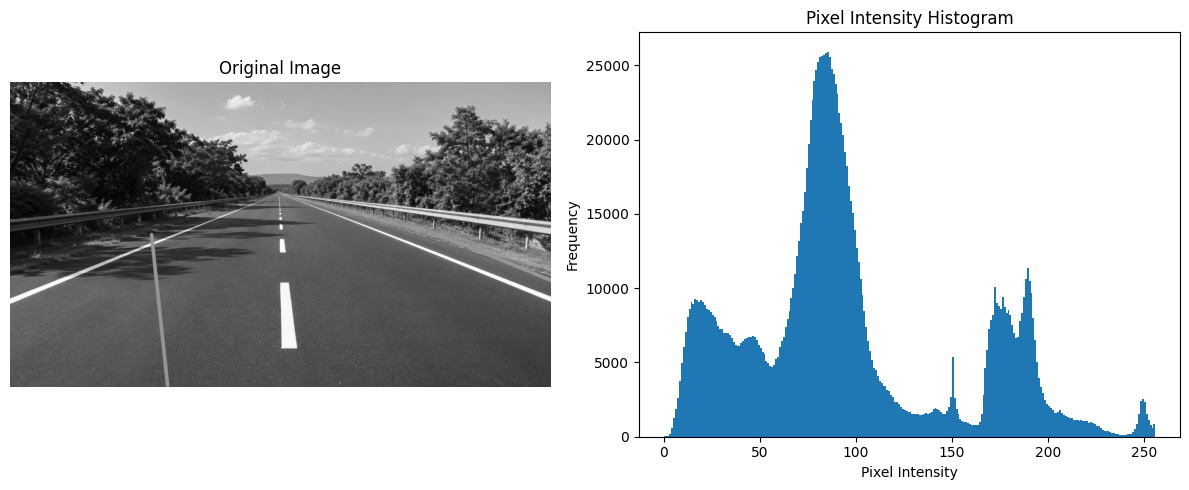

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(pixels, bins=256, range=(0, 256))
plt.title("Pixel Intensity Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()